In [91]:
import matplotlib.pyplot as plt
import missingno as msno
import pandas as pd

In [92]:
datos_por_hoja = pd.read_excel("../data/Base_de_Datos.xlsx", sheet_name=None)

# Ver los nombres de las hojas disponibles
print(datos_por_hoja.keys())

dict_keys(['Ensamble', 'OREC', 'F&A', 'RC Energia', 'RC GAS'])


# Crear DataFrames

## Ensamble

In [93]:
df_ensamble = datos_por_hoja["Ensamble"]
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_ensamble.columns = df_ensamble.iloc[0]

# 2. Eliminar la fila 0 (que contiene los encabezados duplicados) y resetear el índice
df_ensamble = df_ensamble.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna
df_ensamble = df_ensamble.dropna(how="all", axis=1)

# 4. Eliminar el nombre del eje de columnas
df_ensamble.columns.name = None

In [94]:
df_ensamble

,Año,Mes,Proceso,Indice,KWH,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales),KWH/Equ (Presupuesto),Costo por KWH,Costo total KWH
0,2019,Oct,Linea 1,0.34,309181,105121.54,NaN,0,NaN,NaN,NaN
1,2019,Oct,Linea 2,0.19,309181,58744.486037,NaN,0,NaN,NaN,NaN
2,2019,Oct,Linea 3,0.2,309181,61836.2,NaN,0,NaN,NaN,NaN
3,2019,Oct,Linea 4,0.27,309181,83478.87,NaN,0,NaN,NaN,NaN
4,2019,Oct,Ensamble,1,309181,309181,124270,2.487978,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
405,2026,Jul,Linea 1,0.34,279900,95166.0,32581.806,2.920833,2.241444,529.577718,50397793.117626
406,2026,Jul,Linea 2,0.19,279900,53181.086942,20681.034,2.571491,2.102712,529.577718,28163518.667088
407,2026,Jul,Linea 3,0.2,279900,55980.0,0,0,1.499576,529.577718,29645760.657427
408,2026,Jul,Linea 4,0.27,279900,75573.0,28363.0464,2.664488,2.203593,529.577718,40021776.887526


## OREC

In [95]:
df_orec = datos_por_hoja["OREC"]
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_orec.columns = df_orec.iloc[0]

# 2. Eliminar la fila 0 (que contiene los encabezados duplicados) y resetear el índice
df_orec = df_orec.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna
df_orec = df_orec.iloc[:, 1:]

# 4. Eliminar el nombre del eje de columnas
df_orec.columns.name = None

In [96]:
df_orec

,Año,Mes,Dia,Turno,Proceso,Indice,KWH,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales),KWH/Equ (Presupuesto),Costo por KWH,Costo total KWH
0,2019,Oct,NaN,NaN,Rejillas,0.146401,577644,84567.536114,NaN,0,NaN,NaN,0
1,2019,Oct,NaN,NaN,Cinta,0.107361,577644,62016.19315,NaN,0,NaN,NaN,0
2,2019,Oct,NaN,NaN,Planta Oxido,0.370882,577644,214237.758155,NaN,0,NaN,NaN,0
3,2019,Oct,NaN,NaN,Empaste Casting,0.097601,577644,56378.357409,NaN,0,NaN,NaN,0
4,2019,Oct,NaN,NaN,Empaste Expanded,0.117121,577644,67654.028891,NaN,0,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
562,2026,Jun,NaN,NaN,Planta Oxido,0.43,506000,217580.0,14758.338487,14.742852,11.534428,544.411093,118452965.685795
563,2026,Jun,NaN,NaN,Empaste Casting,0.11,506000,55660,18509.89337,3.007041,3.036575,544.411093,30301921.454506
564,2026,Jun,NaN,NaN,Empaste Expanded,0,506000,0,NaN,0,7.167127,544.411093,0
565,2026,Jun,NaN,NaN,Empaste Cominco,0.16,506000,80960.0,17931.005457,4.515084,3.795,544.411093,44075522.115645


**RECUERDE QUE COSTO POR KWH VA CAMBIANDO, SE DEBE CONSULTAR**

## F&A

In [97]:
df_fa = datos_por_hoja[r"F&A"]
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_fa.columns = df_fa.iloc[0]

# 2. Eliminar la fila 0 (que contiene los encabezados duplicados) y resetear el índice
df_fa = df_fa.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna
df_fa = df_fa.iloc[:, 1:]

# 4. Eliminar el nombre del eje de columnas
df_fa.columns.name = None

In [98]:
df_fa

,Año,Mes,Dia,Turno,Proceso,Participacion,KWH,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales),KWH/Equ (Presupuesto),Costo por KWH,Costo total KWH
0,2019,Oct,NaN,NaN,FORMACION,0.85,1193455,1014436.75,NaN,0,NaN,NaN,0
1,2019,Oct,NaN,NaN,LINEA ACABADO PRINCIPAL,0.15,1193455,179018.25,NaN,0,NaN,NaN,0
2,2019,Oct,NaN,NaN,F&A,1,1193455,1193455,56766,21.024117,NaN,NaN,0
3,2019,Nov,NaN,NaN,FORMACION,0.85,1174219,998086.15,NaN,0,NaN,NaN,0
4,2019,Nov,NaN,NaN,LINEA ACABADO PRINCIPAL,0.15,1174219,176132.85,NaN,0,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,2026,Jun,NaN,NaN,LINEA ACABADO PRINCIPAL,0.15,1067147,160072.05,24206.549184,6.612758,11.089568,544.411093,87144999.751378
242,2026,Jun,NaN,NaN,F&A,1,1067147,1067147,56040.758732,19.042337,18.33207,544.411093,580966665.009187
243,2026,Jul,NaN,NaN,FORMACION,0.85,1144675,972973.75,29045.206629,33.4986,25.574571,529.577718,515265218.26472
244,2026,Jul,NaN,NaN,LINEA ACABADO PRINCIPAL,0.15,1144675,171701.25,23561.237529,7.287446,11.089568,529.577718,90929156.164362


**RECUERDE QUE DIA, TURNO Y KWH por proceso SALEN DEL SCADA**

> Pregunte si Costo por KWH tambien va cambiando en esta planta

## RC Energia

In [99]:
df_rc_eng = datos_por_hoja["RC Energia"]
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_rc_eng.columns = df_rc_eng.iloc[0]

# 2. Eliminar la fila 0 (que contiene los encabezados duplicados) y resetear el índice
df_rc_eng = df_rc_eng.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna
df_rc_eng = df_rc_eng.iloc[:, 1:]

# 4. Eliminar el nombre del eje de columnas
df_rc_eng.columns.name = None

In [100]:
df_rc_eng

,Año,Mes,Dia,Turno,Proceso,Indice,KWH,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales),KWH/Equ (Presupuesto),Costo por KWH,Costo total KWH
0,2017,Oct,NaN,NaN,RC,1,321914.0,321914.0,3120,103.177564,NaN,NaN,0
1,2017,Nov,NaN,NaN,RC,1,428732.0,428732.0,2869,149.43604,NaN,NaN,0
2,2017,Dec,NaN,NaN,RC,1,243970.0,243970.0,2634,92.623386,NaN,NaN,0
3,2018,Jan,NaN,NaN,RC,1,380516.0,380516.0,2535,150.104931,NaN,NaN,0
4,2018,Feb,NaN,NaN,RC,1,407382.0,407382.0,2695,151.162152,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,2026,Feb,NaN,NaN,RC,1,369676,369676,1799,205.489717,NaN,NaN,0
101,2026,Mar,NaN,NaN,RC,1,259469,259469,391,663.603581,NaN,NaN,0
102,2026,Apr,NaN,NaN,RC,1,230318,230318,662,347.912387,NaN,NaN,0
103,2026,May,NaN,NaN,RC,1,329920,329920,1824,180.877193,NaN,NaN,0


**RECUERDE QUE DIA, TURNO Y KWH SALEN DEL SCADA**

**Costo por KWH tambien va cambiando en esta planta**

> Pregunte si KWH por proceso tambien sale de SCADA como la anterior o si cambia

## RC GAS

In [101]:
df_rc_gas = datos_por_hoja["RC GAS"]
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_rc_gas.columns = df_rc_gas.iloc[0]

# 2. Eliminar la fila 0 (que contiene los encabezados duplicados) y resetear el índice
df_rc_gas = df_rc_gas.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna
df_rc_gas = df_rc_gas.iloc[:, 1:]

# 4. Eliminar el nombre del eje de columnas
df_rc_gas.columns.name = None

In [102]:
df_rc_gas

,Año,Mes,Dia,Turno,Proceso,(m3),Produccion (Equivalente),m3 /Equ (Reales),m3 /Equ (presupuesto),Costo m3,Total Costo m3
0,2017,Oct,NaN,NaN,RC,118659,3120,38.031731,NaN,NaN,0
1,2017,Nov,NaN,NaN,RC,230669,2869,80.400488,NaN,NaN,0
2,2017,Dic,NaN,NaN,RC,65185,2634,24.747532,NaN,NaN,0
3,2018,Ene,NaN,NaN,RC,219753,2535,86.687574,NaN,NaN,0
4,2018,Feb,NaN,NaN,RC,216807,2695,80.447866,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...
100,2026,Feb,NaN,NaN,RC,212100,1799,117.898833,NaN,1799.419,381656769.9
101,2026,Mar,NaN,NaN,RC,69216.41,391,177.024066,NaN,1799.419,124549323.26579
102,2026,Abr,NaN,NaN,RC,163122.0775,662,246.407972,NaN,1799.419,293524965.572972
103,2026,May,NaN,NaN,RC,147090.495,1824,80.641719,NaN,1799.419,264677431.422405


**RECUERDE QUE DIA, TURNO Y m3 SCADA**

> Costo m3 va cambiando, preguntar como acceder a ella, desde el SCADA?

> m3/Equ (presupuesto) parece estar vacia, consultar como se accede y para que sirve.

# Analisis de calidad general.

## Consistencia en tipos de datos

In [103]:
dfs = {
    "Ensamble": df_ensamble,
    "OREC": df_orec,
    "F&A": df_fa,
    "RC Energia": df_rc_eng,
    "RC GAS": df_rc_gas,
}

In [104]:
for name, frame in dfs.items():
    print("=" * 50)
    print(name)
    print("=" * 50)
    frame.info()
    print("\n\n")

Ensamble
<class 'pandas.DataFrame'>
RangeIndex: 410 entries, 0 to 409
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Año                       410 non-null    object
 1   Mes                       410 non-null    str   
 2   Proceso                   410 non-null    str   
 3   Indice                    410 non-null    object
 4   KWH                       410 non-null    object
 5   KWH por proceso           410 non-null    object
 6   Produccion (Equivalente)  218 non-null    object
 7   KWH/Equ (Reales)          410 non-null    object
 8   KWH/Equ (Presupuesto)     50 non-null     object
 9   Costo por KWH             120 non-null    object
 10  Costo  total KWH          381 non-null    object
dtypes: object(9), str(2)
memory usage: 39.4+ KB



OREC
<class 'pandas.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 13 columns):
 #   Column                    Non-Null Coun

Se requiere pasar todas las columnas al tipo de datos correcto, se hara en el Notebook individual de cada hoja

## Cuantificar nulos

In [ ]:
def nan_diagnosis(df: pd.DataFrame, name: str = "el df") -> None:
    """Return a graph that show null values."""
    n_cols = len(df.columns)
    ancho = max(10, int(n_cols * 0.35))
    alto = 5

    tamano_letra = max(6, 10 - n_cols // 10)

    # Porcentaje de nulos por columna
    pct_nulos = df.isnull().mean() * 100

    try:
        ax = msno.matrix(df, figsize=(ancho, alto), fontsize=tamano_letra) or plt.gca()
        plt.title(f"Patrón de Faltantes en {name}")

        if len(ax.get_xticks()) == n_cols:
            ax.set_xticks(range(n_cols))
            ax.set_xticklabels(
                [f"{c} ({p:.1f}%)" for c, p in zip(df.columns, pct_nulos, strict=False)],
                rotation=45,
                ha="left",
                fontsize=tamano_letra,
            )

        plt.show()

    except Exception:
        plt.figure(figsize=(ancho, alto))
        missing_pattern = df.isnull()

        plt.imshow(missing_pattern.astype(int), aspect="auto", cmap="RdYlGn_r")

        plt.xticks(
            ticks=range(n_cols),
            labels=[
                f"{c} ({p:.1f}%)" for c, p in zip(missing_pattern.columns, pct_nulos, strict=False)
            ],
            rotation=90,
            fontsize=tamano_letra,
            ha="center",
        )
        plt.yticks([])
        plt.title("Patrón de Faltantes (blanco = faltante)")
        plt.colorbar(label="1=Faltante, 0=Presente")

        plt.tight_layout()  # Evita que las etiquetas se corten abajo
        plt.show()

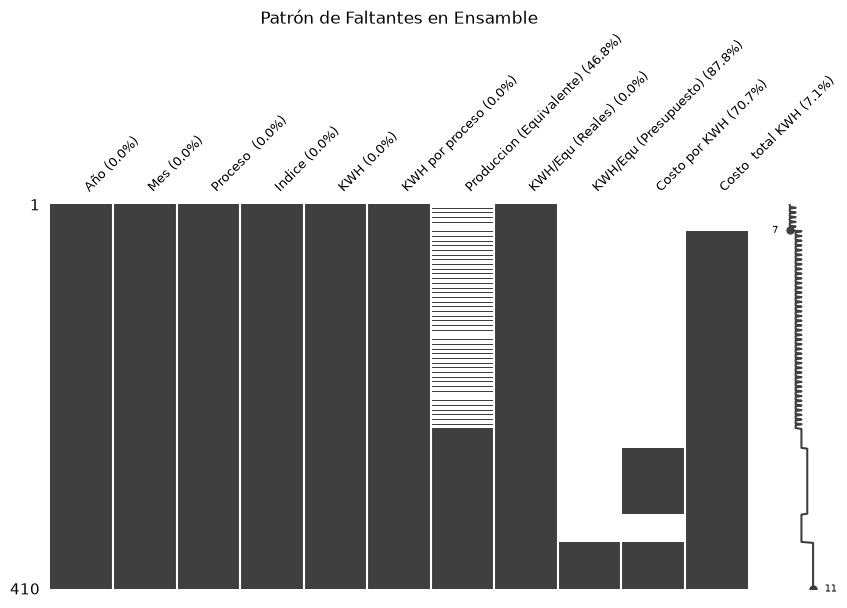

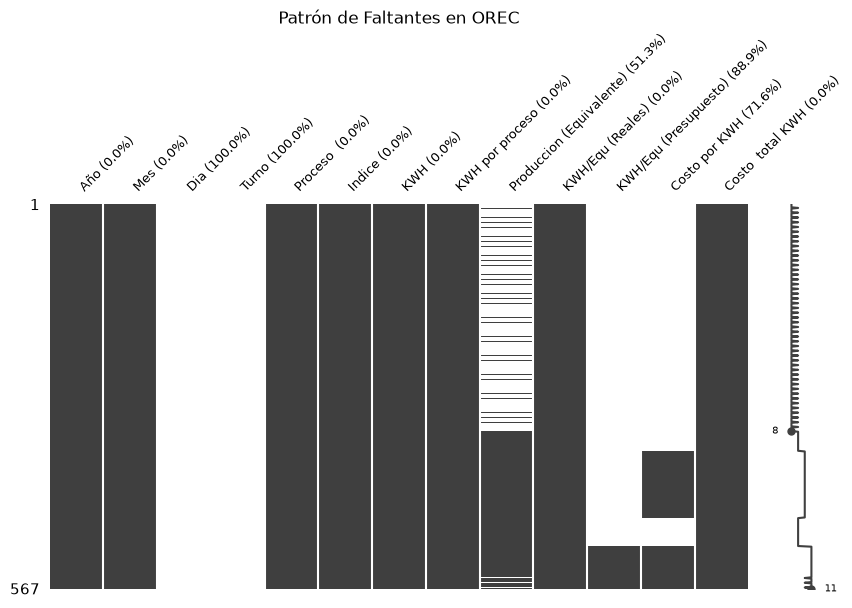

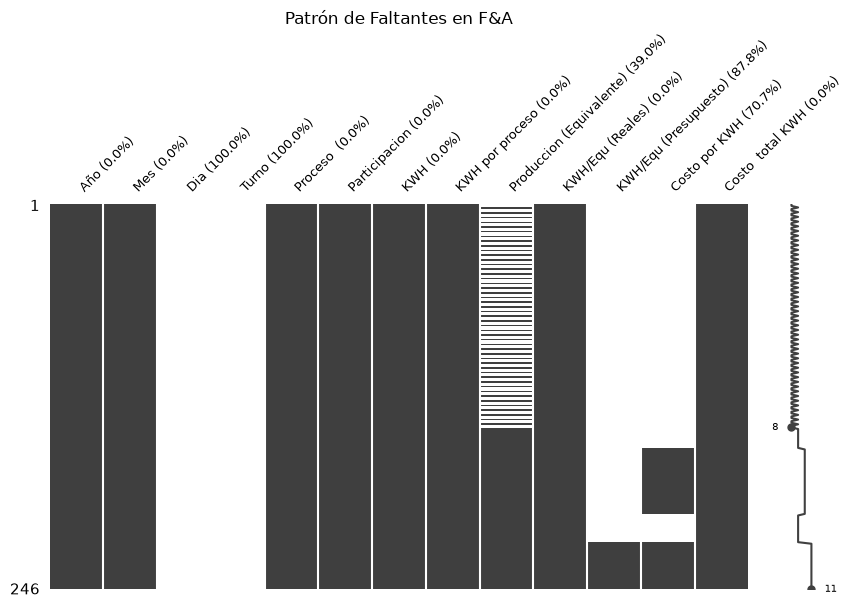

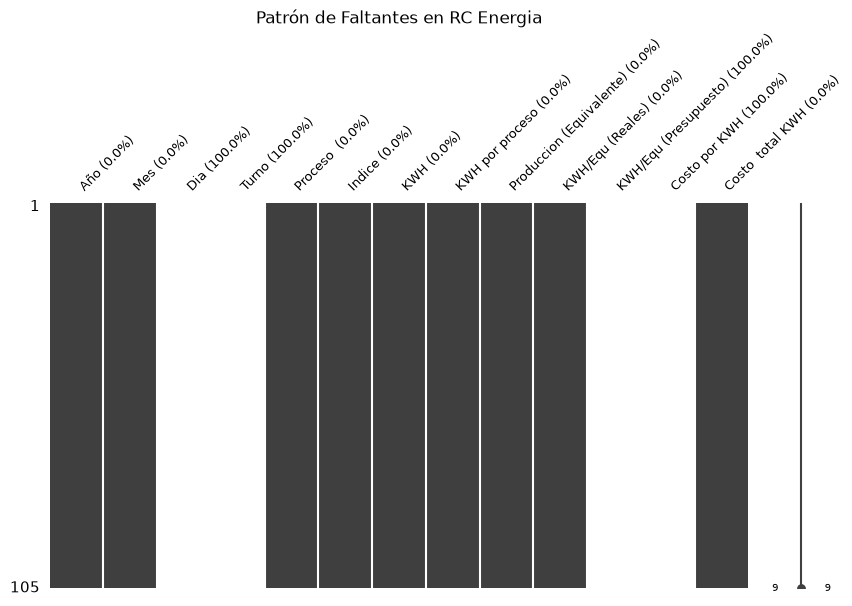

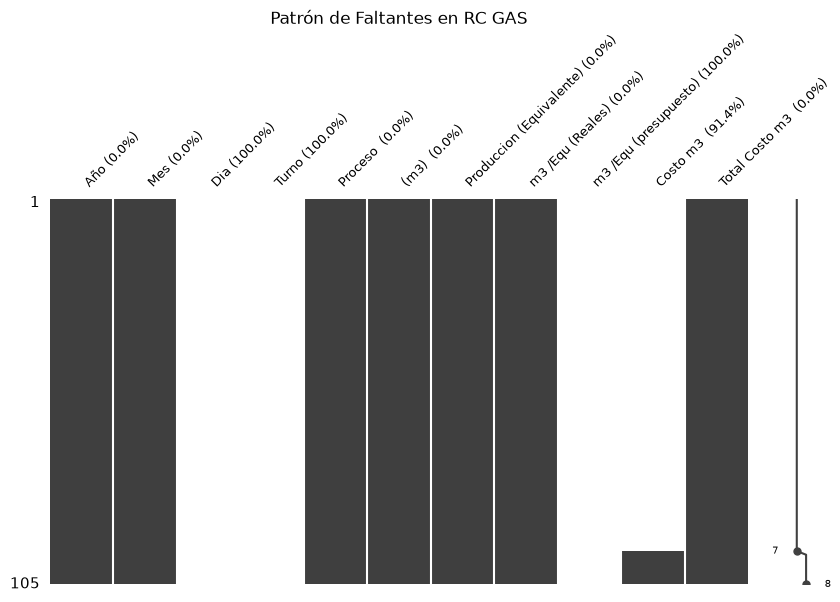

In [106]:
for name, frame in dfs.items():
    nan_diagnosis(frame, name)

Preguntar que significan los nulos, si los que vienen del SCADA estan pendientes de integrar pero se tienen (posiblemente cols con 100% de  nulos).

En columnas parcialmente vacias preguntar si son datos que faltan del SCADA, errores o que significan los nulos en el contexto.

## Evaluar Temporalidad (primer vistazo basico)

In [107]:
for name, frame in dfs.items():
    print("=" * 50)
    print(name)
    print("=" * 50)
    display(frame.groupby(["Año", "Mes"]).size())
    print("\n\n")

Ensamble


Año   Mes
2019  Nov     5
      Oct     5
2020  Abr     5
      Ago     5
      Dic    10
             ..
2026  Feb     5
      Jul     5
      Jun     5
      Mar     5
      May     5
Length: 81, dtype: int64




OREC


Año   Mes
2019  Dic    6
      Nov    7
      Oct    7
2020  Abr    7
      Ago    7
            ..
2026  Ene    7
      Feb    7
      Jun    7
      Mar    7
      May    7
Length: 82, dtype: int64




F&A


Año   Mes
2019  Dic    3
      Nov    3
      Oct    3
2020  Abr    3
      Ago    3
            ..
2026  Feb    3
      Jul    3
      Jun    3
      Mar    3
      May    3
Length: 82, dtype: int64




RC Energia


Año   Mes
2017  Dec    1
      Nov    1
      Oct    1
2018  Apr    1
      Aug    1
            ..
2026  Feb    1
      Jan    1
      Jun    1
      Mar    1
      May    1
Length: 105, dtype: int64




RC GAS


Año   Mes
2017  Dic    1
      Nov    1
      Oct    1
2018  Abr    1
      Ago    1
            ..
2026  Ene    1
      Feb    1
      Jun    1
      Mar    1
      May    1
Length: 105, dtype: int64

In [108]:
for name, frame in dfs.items():
    print("=" * 50)
    print(name)
    print("=" * 50)
    print("Promedio de cortes (puede que dias, revisar) por mes año: ")
    print(frame.groupby(["Año", "Mes"]).size().mean())
    print("\n")

Ensamble
Promedio de cortes (puede que dias, revisar) por mes año: 
5.061728395061729


OREC
Promedio de cortes (puede que dias, revisar) por mes año: 
6.914634146341464


F&A
Promedio de cortes (puede que dias, revisar) por mes año: 
3.0


RC Energia
Promedio de cortes (puede que dias, revisar) por mes año: 
1.0


RC GAS
Promedio de cortes (puede que dias, revisar) por mes año: 
1.0




In [109]:
for name, frame in dfs.items():
    print("=" * 50)
    print(name)
    print("=" * 50)

    # Tabla Año vs Mes con la cantidad de cortes
    conteo_tabla = pd.crosstab(frame["Año"], frame["Mes"])
    print("Conteo de cortes por Año y Mes:")
    print(conteo_tabla)

    # Promedio general de cortes por periodo (Año-Mes)
    promedio_global = frame.groupby(["Año", "Mes"]).size().mean()
    print("\nPromedio global de cortes por periodo (Año-Mes):")
    print(f"    {promedio_global:.2f}")
    print("\n")

Ensamble
Conteo de cortes por Año y Mes:
Mes   Abr  Ago  Dic  Ene  Feb  Jul  Jun  Mar  May  Nov  Oct  Sep
Año                                                             
2019    0    0    0    0    0    0    0    0    0    5    5    0
2020    5    5   10    5    5    5    5    5    5    5    5    5
2021    5    5    5    5    5    5    5    5    5    5    5    5
2022    5    5    5    5    5    5    5    5    5    5    5    5
2023    5    5    5    5    5    5    5    5    5    5    5    5
2024    5    5    5    5    5    5    5    5    5    5    5    5
2025    5    5    5    5    5    5    5    5    5    5    5    5
2026    5    0    0    5    5    5    5    5    5    0    0    0

Promedio global de cortes por periodo (Año-Mes):
    5.06


OREC
Conteo de cortes por Año y Mes:
Mes   Abr  Ago  Dic  Ene  Feb  Jul  Jun  Mar  May  Nov  Oct  Sep
Año                                                             
2019    0    0    6    0    0    0    0    0    0    7    7    0
2020    7    7  

Preguntar la frecuencia temporal que  se registra, con los fatos actuales no es vialble tener reportes diarios.

> preguntar si la conexion con la BD da una mayor frecuencia de datos.

en cuyo caso evaluar que cada tanto se hacen las actualizacines de datos  y ajustar la temporalidad **el objetivo sigue siendo diario**

tambien evaluar que modelo es viable dados los pocos datos y la diferencia de comportamiento (plausible, falta verificacion) de planta a planta.